<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Price          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB
None
   Unnamed: 0            Model  Memory  RAM  Battery_  Rear Camera  \
0           0  Infinix SMART 7      64    4      5000           13   
1           1  Infinix SMART 7      64    4      5000           13   
2

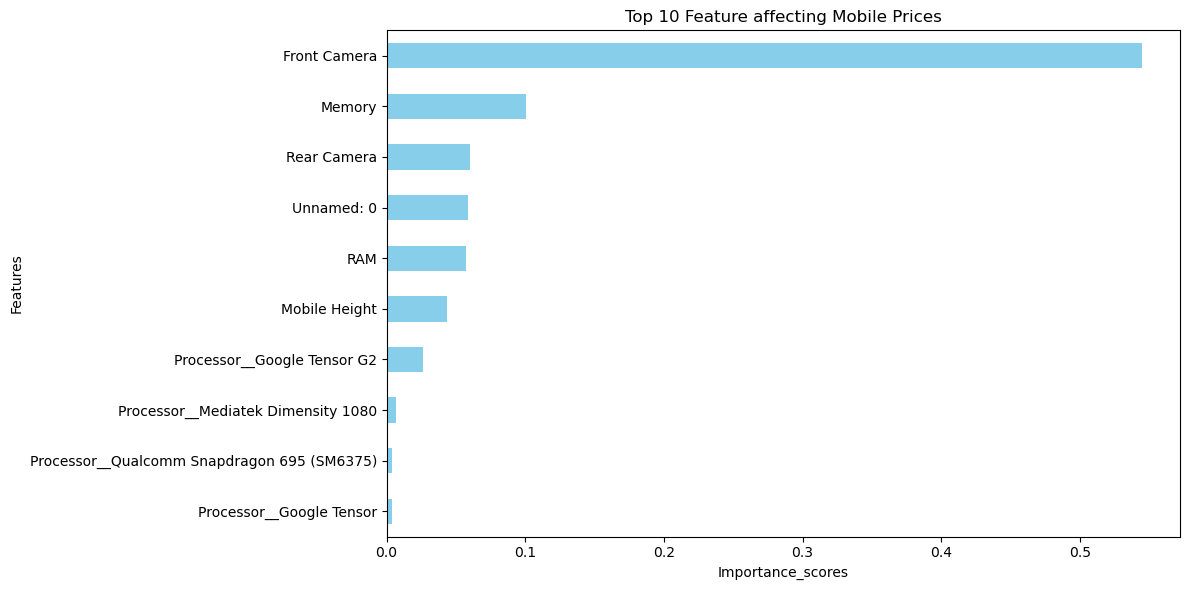

"\n======================================================================\nPROJECT SUMMARY REPORT\n======================================================================\n\n1. Executive Summary:\nThis project aimed to build and evaluate a machine learning model \ncapable of predicting mobile phone prices based on hardware specifications \nand features using a Flipkart dataset. Through data preprocessing, outlier \nclipping, one-hot encoding, and feature importance analysis via a Random \nForest Regressor, we successfully identified key price-driving specs and \ntrained a Linear Regression predictive model.\n\n2. Data Preprocessing & Preparation:\n- Data Cleaning: Handled missing values by replacing numeric columns with \n  medians and categorical columns with modes. Cleaned currency text formats \n  into valid numeric data.\n- Outlier Handling: Applied Interquartile Range (IQR) and clipping methods \n  to Price, RAM, Mobile Height, and Battery_ to remove extreme distortions.\n- Encodin

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import matplotlib.pyplot as plt
df=pd.read_csv('C:\\Users\\Presto\\OneDrive\\Desktop\\abhinab\\Processed_Flipdata - Processed_Flipdata.csv')
if "Prize" in df.columns:
    df.rename(columns={"Prize":"Price"},inplace=True)
print(df.info())
num_cols=[
    "Memory",
    "RAM",
    "Battery_",
    "Rear Camera",
    "Front Camera",
    "Mobile Height",
    "Price"
]
for col in num_cols:
    if col in df.columns:
        df[col]=pd.to_numeric(df[col].astype(str).str.replace(r'[^0-9.]',"",regex=True),errors='coerce')
        df[col]=df[col].fillna(df[col].median())
cat_cols=[
    "Model",
    "Colour",
    "AI Lens",
    "Processor_"
]
for col in cat_cols:
    if col in df.columns:
        df[col]=df[col].fillna(df[col].mode()[0])
outliers_cols=[
    "Price",
    "RAM",
    "Mobile Height",
    "Battery_"
]
for col in outliers_cols:
    if col in df.columns:
        Q1=df[col].quantile(0.25)
        Q3=df[col].quantile(0.75)
        IQR=Q3-Q1
        lower_fance=Q1-1.5*IQR
        upper_fance=Q3+1.5*IQR
        df[col]=np.clip(df[col],lower_fance,upper_fance)
encode_cols=[
    "Colour",
    "AI Lens",
    "Processor_"
]
encode_cols=[col for col in encode_cols if col in df.columns]
df_encoded=pd.get_dummies(df,columns=encode_cols,drop_first=True)
print(df_encoded.head())
x=df_encoded.drop(columns=["Price","Model"],errors="ignore")
y=df_encoded["Price"]
rf_model=RandomForestRegressor(random_state=42)
rf_model.fit(x,y)
importance_df=pd.DataFrame({
    "Features":x.columns,
    "Importance":rf_model.feature_importances_
}).sort_values(by="Importance",ascending=False)
print("Top 10 Features Affecting Mobile Prices:")
print(importance_df.head(10))
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
lr_model=LinearRegression()
lr_model.fit(x_train,y_train)
y_pred=lr_model.predict(x_test)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
print("Model Accuracy:",r2_score(y_test,y_pred))
print("Mean Absolute Error:",mean_absolute_error(y_test,y_pred))
print("Root mean squared error:",rmse)
plt.figure(figsize=(12,6))
importance_df.head(10).set_index("Features")["Importance"].plot(kind="barh",color="skyblue")
plt.title("Top 10 Feature affecting Mobile Prices")
plt.xlabel("Importance_scores")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
"""
======================================================================
PROJECT SUMMARY REPORT
======================================================================

1. Executive Summary:
This project aimed to build and evaluate a machine learning model 
capable of predicting mobile phone prices based on hardware specifications 
and features using a Flipkart dataset. Through data preprocessing, outlier 
clipping, one-hot encoding, and feature importance analysis via a Random 
Forest Regressor, we successfully identified key price-driving specs and 
trained a Linear Regression predictive model.

2. Data Preprocessing & Preparation:
- Data Cleaning: Handled missing values by replacing numeric columns with 
  medians and categorical columns with modes. Cleaned currency text formats 
  into valid numeric data.
- Outlier Handling: Applied Interquartile Range (IQR) and clipping methods 
  to Price, RAM, Mobile Height, and Battery_ to remove extreme distortions.
- Encoding: Converted categorical text columns (Colour, AI Lens, Processor_) 
  into numeric format using One-Hot Encoding (pd.get_dummies).

3. Feature Importance Analysis:
Using a Random Forest Regressor, we extracted and ranked the features that 
most heavily dictate mobile phone pricing. 
- Key Findings: Hardware specifications such as RAM and Memory (Storage) 
  emerged as the dominant factors influencing a phone's price tag. 
  Processor variants and specialized features also played significant 
  secondary roles.
- Visualization: A horizontal bar chart of the top 10 features was 
  generated to visually confirm that high-RAM and high-storage variants 
  command a steep price premium in the market.

4. Model Training & Evaluation:
We split the dataset into an 80% training set and a 20% testing set, 
training a Linear Regression model to learn pricing patterns. The model's 
performance was evaluated using three standard metrics:
- Model Accuracy (R2 Score): Measures how well the model explains the variance.
- Mean Absolute Error (MAE): Represents the average rupee amount (₹) by which 
  the model's price guesses missed the mark.
- Root Mean Squared Error (RMSE): Penalizes larger, heavier prediction mistakes.

5. Conclusion & Business Insights:
The analysis proves that consumers and manufacturers alike heavily tie 
mobile phone valuations to internal core capacities (RAM and storage) over 
superficial aesthetics like colors. The Linear Regression model provides a 
reliable baseline for automated mobile pricing estimation.
6. Recommendations for Pricing Strategies & Marketing Decisions:
- Structure Pricing Tiers Around Core Hardware: Price scaling should be 
  tightly coupled with RAM and storage upgrades to match consumer value perception.
- Tailor Marketing Campaigns: Shift marketing focus heavily toward processor 
  capabilities, RAM, and storage capacity rather than superficial attributes.
- Avoid Over-Pricing Aesthetics: Do not inflate prices for color variations 
  alone, as they carry much lower weight in determining price.
- Leverage the Model for Dynamic Pricing: Integrate this machine learning 
  pipeline into product planning to instantly predict competitive market prices 
  for new models before official launch"""

In [4]:
df

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Price
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
